# EDA de desarrollo v2

Análisis ejecutado de metadatos de entrenamiento y validación. La reserva no interviene en las tablas. Los intervalos se generaron mediante `scripts/eda_particion_v2.py`; este notebook reproduce y contrasta las salidas agregadas, sin requerir las imágenes originales.

In [1]:
from pathlib import Path
import pandas as pd
import json
from IPython.display import display, SVG
R=Path.cwd().parent
D=R/'resultados_analizados/eda_v2'
s=pd.read_csv(D/'retencion_y_composicion.csv')
assert set(s.particion)=={'train','validation'}
assert s.groupby('particion').recortes.sum().to_dict()=={'train':14539,'validation':2049}
display(s.round(4))

,particion,clase,anotaciones,recortes,retencion,retencion_ic95_inf,retencion_ic95_sup,proporcion,proporcion_ic95_inf,proporcion_ic95_sup
0,train,tumor_nonMitotic,14187,6977,0.4918,0.4764,0.5051,0.4799,0.4222,0.5372
1,train,lymphocyte,9946,4460,0.4484,0.4344,0.4629,0.3068,0.2494,0.3641
2,train,nonTILnonMQ_stromal,6608,3102,0.4694,0.4498,0.4887,0.2134,0.1777,0.2492
3,validation,tumor_nonMitotic,2340,1108,0.4735,0.4315,0.5183,0.5408,0.4317,0.6474
4,validation,lymphocyte,1327,597,0.4499,0.3872,0.4980,0.2914,0.1687,0.4290
5,validation,nonTILnonMQ_stromal,710,344,0.4845,0.4383,0.5303,0.1679,0.1165,0.2203


In [2]:
p=pd.read_csv(D/'recortes_por_paciente.csv')
assert p.groupby('paciente').particion.nunique().max()==1
assert p.groupby('tss').particion.nunique().max()==1
display(p.groupby('particion').recortes.agg(['count','min','median','max']))
display(pd.read_csv(D/'seleccion_por_motivo.csv'))

,count,min,median,max
particion,,,,
train,83,7,121.0,547
validation,21,2,79.0,231


,particion,estado,anotaciones
0,train,caja_fuera_de_imagen,441
1,train,caja_invalida,84
2,train,caja_no_contenida,4
3,train,incluida,14539
4,train,requiere_relleno,15673
5,validation,caja_fuera_de_imagen,56
6,validation,caja_invalida,2
7,validation,caja_no_contenida,4
8,validation,incluida,2049
9,validation,requiere_relleno,2266


{
  "fuente_sha256": "4e1574051a66740c050c3cd66fb11d423f2c57f313a4d71c02f9b2f3a913c77c",
  "alcance": "Solo entrenamiento y validación; metadatos, sin análisis de píxeles ni predicciones de reserva",
  "bootstrap": {
    "repeticiones": 5000,
    "semilla": 4101,
    "unidad": "paciente dentro de cada partición",
    "intervalo": "percentil 95%; razón de totales de los pacientes remuestreados",
    "limitacion": "Condicional a los TSS observados; no estima incertidumbre entre centros ni corrige decisiones históricas"
  },
  "pacientes": {
    "train": 83,
    "validation": 21
  },
  "resumen_recortes_por_paciente": {
    "train": {
      "min": 7,
      "mediana": 121.0,
      "max": 547
    },
    "validation": {
      "min": 2,
      "mediana": 79.0,
      "max": 231
    }
  }
}


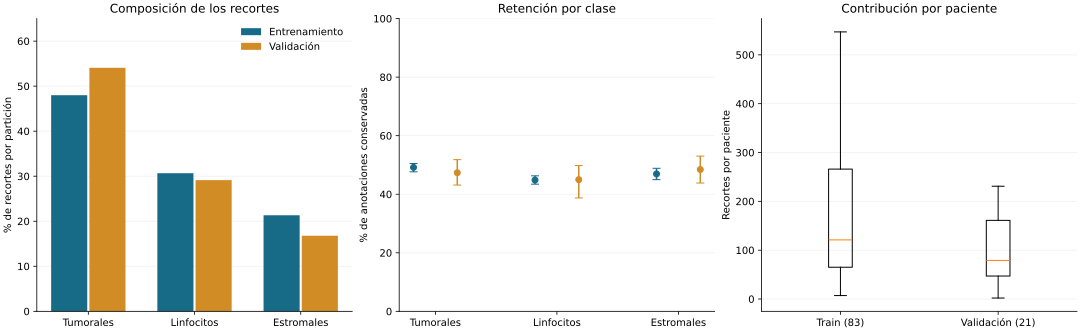

In [3]:
display(SVG(filename=str(R/'book/figuras/eda_desarrollo_v2.svg')))
print(json.dumps(json.loads((D/'metodo.json').read_text()),ensure_ascii=False,indent=2))

La composición y la contribución desigual de los pacientes justifican informar métricas por clase y estimar incertidumbre por paciente. La mayor proporción tumoral en validación no constituye evidencia de un mecanismo biológico: describe la selección disponible. Los resultados no incluyen calidad de píxeles ni desempeño predictivo.

## EDA de píxeles y diagnósticos por paciente

Datos recibidos en `EDA_PIXELES_V2_20261107_104054.zip`. Las estadísticas siguientes corresponden a los nuevos recortes de entrenamiento y validación, no a campos del piloto.

In [4]:
from pathlib import Path
import pandas as pd, numpy as np, json
from sklearn.metrics import confusion_matrix, balanced_accuracy_score
from IPython.display import display, SVG
R=Path.cwd().parent
D=R/'resultados_analizados/eda_pixeles_v2'
r=json.loads((D/'resumen.json').read_text())
a=json.loads((D/'verificacion.json').read_text())
assert a['recortes_verificados']==16588 and a['pacientes']==104
display(pd.DataFrame({'canal':list('RGB'),'media':r['normalizacion_train']['media_RGB_0_1'],'sd':r['normalizacion_train']['sd_RGB_0_1']}))
print(json.dumps(a,ensure_ascii=False,indent=2))

{
  "archivo_fuente": "EDA_PIXELES_V2_20261107_104054.zip",
  "sha256_zip": "130428c3b3f9b7fbe81742f7a456c8d87549bf6e28233fa4e84e2c918c028ccd",
  "recortes_verificados": 16588,
  "pacientes": 104,
  "script_coincide": true,
  "manifiesto_coincide": true,
  "media_sd_rgb_recalculadas": true,
  "histogramas_conteos_correctos": true,
  "diagnosticos": {
    "diagnostico_dominio": "Matriz y balanced accuracy recalculadas",
    "diagnostico_sitio": "Matriz y balanced accuracy recalculadas"
  },
  "similitud_hamming_recalculada": {
    "pares": 29790411,
    "candidatos": 0
  },
  "alcance": "Se recalcularon resultados desde descriptores y hashes; no se recibieron ni decodificaron los píxeles. AUC adversarial registrada por el script, no recalculable desde predicciones duras exportadas."
}


,canal,media,sd
0,R,0.639203,0.213974
1,G,0.459171,0.221497
2,B,0.627745,0.174289


In [5]:
for key in ['diagnostico_dominio','diagnostico_sitio']:
    d=pd.read_csv(D/(key+'_predicciones.csv'))
    cm=confusion_matrix(d.real,d.prediccion,labels=r[key]['clases'])
    assert np.array_equal(cm,r[key]['confusion'])
    assert np.isclose(balanced_accuracy_score(d.real,d.prediccion),r[key]['balanced_accuracy'])
    print(key, 'pacientes:',len(d),'balanced accuracy:',balanced_accuracy_score(d.real,d.prediccion))
    display(pd.DataFrame(cm,index=r[key]['clases'],columns=r[key]['clases']))
print('AUC adversarial reportada:',r['diagnostico_dominio']['auc_validation'])
print('Similitud:',r['similitud'])

diagnostico_dominio pacientes: 104 balanced accuracy: 0.6769936890418818
diagnostico_sitio pacientes: 77 balanced accuracy: 0.39826388888888886
AUC adversarial reportada: 0.7096959265633964
Similitud: {'metodo': 'dHash 64 bits, distancia Hamming <=4, entre train y validation', 'pares_examinados': 29790411, 'candidatos': 0, 'filas_exportadas': 0, 'limite_exportacion': 500, 'interpretacion': 'Candidatos a inspección visual; no prueba duplicación. No detecta todas las rotaciones, escalas o solapamientos. No elimina imágenes.'}


,train,validation
train,61,22
validation,8,13


,A2,AR,C8,D8,E2,EW,GM,LL
A2,10,0,2,1,1,3,0,1
AR,0,3,2,0,0,1,2,0
C8,0,0,2,2,0,0,0,1
D8,0,2,3,5,2,0,0,0
E2,0,2,0,5,7,1,0,0
EW,3,1,2,0,1,2,0,0
GM,0,2,1,0,0,2,0,1
LL,0,0,0,0,0,0,1,3


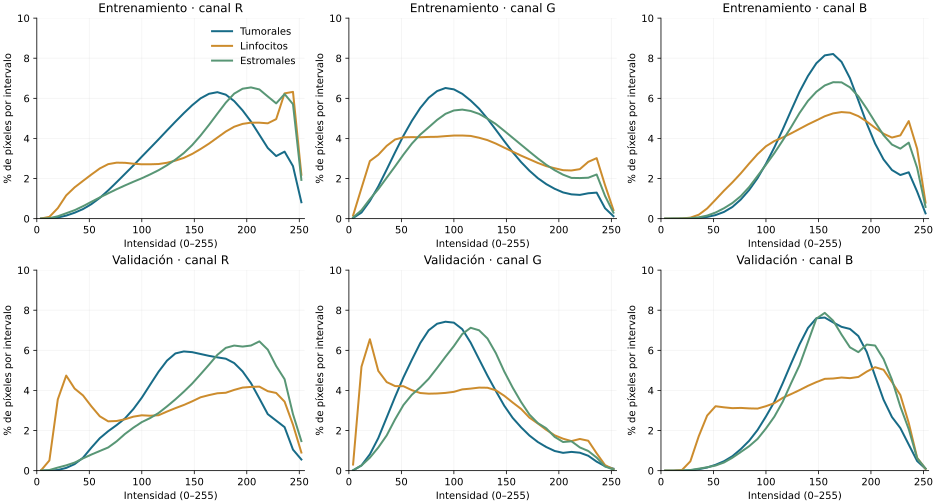

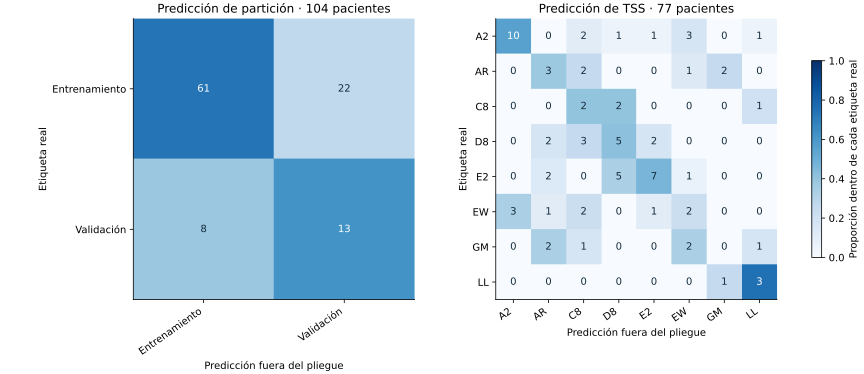

In [6]:
display(SVG(filename=str(R/'book/figuras/histogramas_pixeles_v2.svg')))
display(SVG(filename=str(R/'book/figuras/diagnosticos_pixeles_v2.svg')))

La AUC adversarial de 0,7097 describe diferencias detectables entre grupos mediante descriptores agregados por paciente. No atribuye causalidad a tinción o procedencia. La señal de TSS no prueba que las CNN la utilicen. No encontrar candidatos dHash con distancia ≤4 complementa la verificación exacta, sin garantizar ausencia de todas las similitudes. La AUC adversarial se conserva del resumen original; no se recalcula a partir de etiquetas duras.

## Incertidumbre y heterogeneidad multivariada

Se trabaja sobre predicciones fuera del pliegue y descriptores agregados por paciente. No se abren imágenes de reserva ni se reentrenan redes.

{"dominio": {"pacientes": 104, "clases": 2, "balanced_accuracy": 0.6769936890418818, "ic95_percentil": [0.5579388984509467, 0.7845668387837063], "sha256": "9ce15c8997cb3794c51e2f2c16fcf93f5c3ccb9192c1e44b4e852fba4c5bb7b4"}, "sitio": {"pacientes": 77, "clases": 8, "balanced_accuracy": 0.39826388888888886, "ic95_percentil": [0.2937413194444445, 0.5038194444444444], "sha256": "2bd1ef67066bb861de374b7279a5d8de11435fa3c49e3c28a83fb027c6daa67f"}, "metodo": {"semilla": 4101, "replicas": 5000, "unidad": "paciente", "intervalos": "Remuestreo estratificado por etiqueta real de predicciones OOF fijas; sin reentrenamiento. Condicionados a TSS y partición observados; no incluyen incertidumbre de ajuste ni entre centros.", "outliers": "Priorización exploratoria, no exclusión. Umbral empírico; no p-valores ni diagnóstico de mala calidad.", "reserva_abierta": false}}
{'train': 5, 'validation': 1}


,diagnostico,pacientes,exactitud_balanceada,IC95_inferior,IC95_superior
0,dominio,104,0.676994,0.557939,0.784567
1,sitio,77,0.398264,0.293741,0.503819


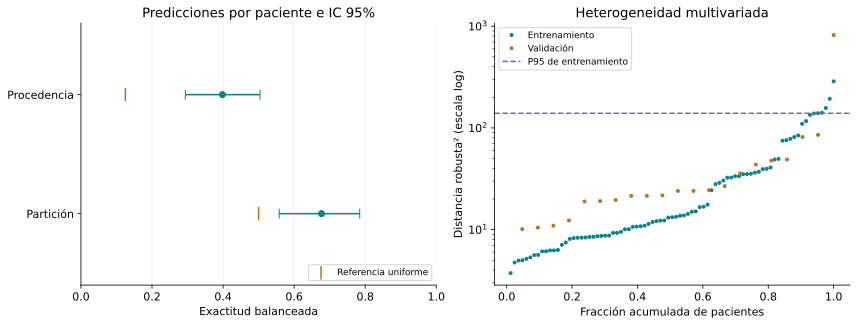

In [7]:
import runpy
runpy.run_path(str(R/'scripts/cerrar_eda_desarrollo.py'), run_name='__main__')
C=R/'resultados_analizados/eda_cierre'
s=json.loads((C/'resumen.json').read_text())
display(pd.DataFrame([{ 'diagnostico':k, 'pacientes':s[k]['pacientes'], 'exactitud_balanceada':s[k]['balanced_accuracy'], 'IC95_inferior':s[k]['ic95_percentil'][0], 'IC95_superior':s[k]['ic95_percentil'][1]} for k in ['dominio','sitio']]))
display(SVG(filename=str(R/'book/figuras/eda_incertidumbre_v2.svg')))
assert s['metodo']['reserva_abierta'] is False


Los intervalos remuestrean pacientes con predicciones fijas; no incluyen incertidumbre del ajuste ni variabilidad entre centros. El umbral multivariado prioriza inspección y no determina exclusiones. El resumen y las distancias por paciente se conservan en `resultados_analizados/eda_cierre`.